# Research Paper Recommendation System
## Combining Paper Text and the Citation Graph on OGB `ogbn-arxiv`

**IE7275 Machine Learning and Data Analytics — Group Project Report**
**Group 4:** Muhammad Hamid, Mark Karu Wagh, Aditya Shashikant Randive
**Dataset:** OGB `ogbn-arxiv` (169,343 Computer Science papers, 1,166,243 citations)

> This report is an executed notebook: every table and figure below is produced by the code cell above it, from the project repository's saved experiment outputs (`results/`). The full pipeline (data preparation, model training, evaluation) is implemented in `src/` and `scripts/`; the commands that regenerate every number are listed in Appendix B.

### Contents
1. Introduction and research question
2. Dataset and preprocessing
3. Task formulation and time-aware split
4. Methodology
5. Evaluation methodology
6. Results
7. Ablation study and error analysis
8. Qualitative examples
9. Limitations and future work
10. Conclusion
Appendices: A. Hyper-parameters · B. Reproducibility · C. Validation results

### Abstract

Researchers cannot read every new paper in their field, so a recommender that surfaces the papers they are most likely to need is valuable. We study **research-paper recommendation on the `ogbn-arxiv` citation graph**: given a new paper's title/abstract and half of its reference list (a stand-in for a researcher's reading history), rank all ~120,000 older papers so that the hidden other half of the reference list appears at the top. We build a strictly **time-aware, leakage-tested** evaluation (train ≤ 2017, validation 2018, test 2019; full ranking over all eligible candidates, no sampled negatives) and compare a popularity baseline, content-only models (TF-IDF, BM25, the provided OGB features and MiniLM sentence embeddings), four graph-only models (co-citation, bibliographic coupling, Personalized PageRank, node2vec), a directional inductive GraphSAGE model, and validation-tuned score fusion.

Text alone is far better than popularity (MiniLM NDCG@20 = 0.176 vs. 0.084), and the citation graph is stronger still: Personalized PageRank (PPR) reaches NDCG@20 = 0.285. **Combining text and graph gives the best model**: fusing MiniLM similarity with PPR (weights chosen on validation) reaches NDCG@20 = 0.330, and adding a small popularity term gives our best result, NDCG@20 = 0.338 and Recall@20 = 0.401 on the 2019 test queries (+19% over PPR and +92% over text alone). Our GNN learns a useful hybrid representation (NDCG@20 = 0.151 ± 0.003 over 3 seeds) but does not beat the simple graph heuristic on its own; used as an extra fusion component it matched the best fusion on validation (test evaluation left as future work). The answer to our research question is therefore **yes — text and citation signals are complementary**, but the most effective way to combine them in our setting is a simple, well-normalised score fusion rather than an end-to-end GNN.

## 1. Introduction and research question

Thousands of new Computer Science papers appear on arXiv every month. A researcher who has read a set of papers needs help finding the *other* papers that are relevant to their work. Two complementary signals are available:

* **Content** — what a paper is about, expressed in its title and abstract. Text similarity can find papers on the same topic even if nobody has connected them yet, but it cannot tell an influential paper from an obscure one, and different communities describe the same idea in different words.
* **Citation graph** — how papers are connected. If the papers a researcher has read are frequently cited together with another paper, that paper is probably relevant, even when its wording is different. But the graph is sparse for new papers (the *cold-start* problem) and favours already-popular work.

**Research question.** *Does combining semantic information from paper text with citation-network information produce better recommendations than content-only, graph-only, and popularity-based baselines, when evaluated in a realistic, time-aware setting?*

To answer it we (i) build an evaluation protocol in which no future information can leak into the models, (ii) build and tune content-only and graph-only baselines, (iii) build two hybrid models — validation-tuned score fusion and an inductive Graph Neural Network (GNN) that uses text embeddings as node features — and (iv) analyse when and why each signal helps (ablations, breakdowns and qualitative examples).

## 2. Dataset and preprocessing

We use OGB `ogbn-arxiv`. Each node is an arXiv CS paper, each directed edge `A → B` means *paper A cites paper B*, every paper has a 128-dimensional feature vector (the average of skip-gram word embeddings of its title and abstract) and a publication year. The raw titles and abstracts are downloaded separately (`titleabs.tsv.gz`) and joined to nodes through the official `nodeidx2paperid` mapping.

**Important preprocessing decisions**

* The graph is kept **directed**. The undirected version used in OGB node-classification examples would mix "cites" and "is cited by", which matters both for modelling and for leakage control.
* Text is the title followed by the abstract. No papers are removed; every node joins to a non-empty title and abstract (checked below).
* Nothing else is filtered at the dataset level; filtering happens only when defining *queries* (Section 3).

In [1]:
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown

from src.utils import load_config, set_seed
from src.data import load_arxiv, load_or_build_split, eligible_references
from src.graph import build_train_graph, build_eval_graph
from src.plotting import style, SERIES

%matplotlib inline
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.precision", 4)
cfg = load_config()
set_seed(cfg["seed"])
plt = style()
print("torch", torch.__version__, "| config seed", cfg["seed"])

torch 2.5.1 | config seed 0


In [2]:
# Load the graph, features, years and the joined titles/abstracts
d = load_arxiv(cfg["paths"]["data_root"])
src, dst = d.edge_index

summary = pd.DataFrame({
    "Value": [f"{d.num_nodes:,}", f"{d.edge_index.shape[1]:,}", d.x.shape[1],
              f"{d.year.min()} - {d.year.max()}", f"{int(d.has_text.sum()):,}", int((~d.has_text).sum()),
              f"{np.mean([len(d.title[i].split()) + len(d.abstract[i].split()) for i in range(d.num_nodes)]):.0f}"]},
    index=["Papers (nodes)", "Citations (directed edges)", "Feature dimensions", "Publication years",
           "Papers with title+abstract", "Papers missing text", "Mean words (title+abstract)"])
display(summary)

,Value
Papers (nodes),"169,343"
Citations (directed edges),"1,166,243"
Feature dimensions,128
Publication years,1971 - 2020
Papers with title+abstract,"169,343"
Papers missing text,0
Mean words (title+abstract),170


In [3]:
# Data validation checks
edges = pd.DataFrame({"src": src, "dst": dst})
checks = {
    "Duplicate edges": int(edges.duplicated().sum()),
    "Self-citations": int((src == dst).sum()),
    "Empty titles": sum(1 for t in d.title if not t),
    "Empty abstracts": sum(1 for a in d.abstract if not a),
    "Citing paper newer than cited (expected direction)": f"{(d.year[src] > d.year[dst]).mean():.1%}",
    "Same-year citations": f"{(d.year[src] == d.year[dst]).mean():.1%}",
    "Citing paper OLDER than cited (data noise)": f"{(d.year[src] < d.year[dst]).mean():.1%}",
}
display(pd.DataFrame({"Result": checks}))

,Result
Duplicate edges,0
Self-citations,0
Empty titles,0
Empty abstracts,0
Citing paper newer than cited (expected direction),87.1%
Same-year citations,11.1%
Citing paper OLDER than cited (data noise),1.8%


The checks confirm the edge direction (87% of citations point from a newer paper to an older one) and that there are no duplicates, self-loops or missing text. 1.8% of edges point "into the future" — an artefact of year-level timestamps and paper revisions. These, and same-year citations, can never be valid recommendations under our time-aware protocol (Section 3).

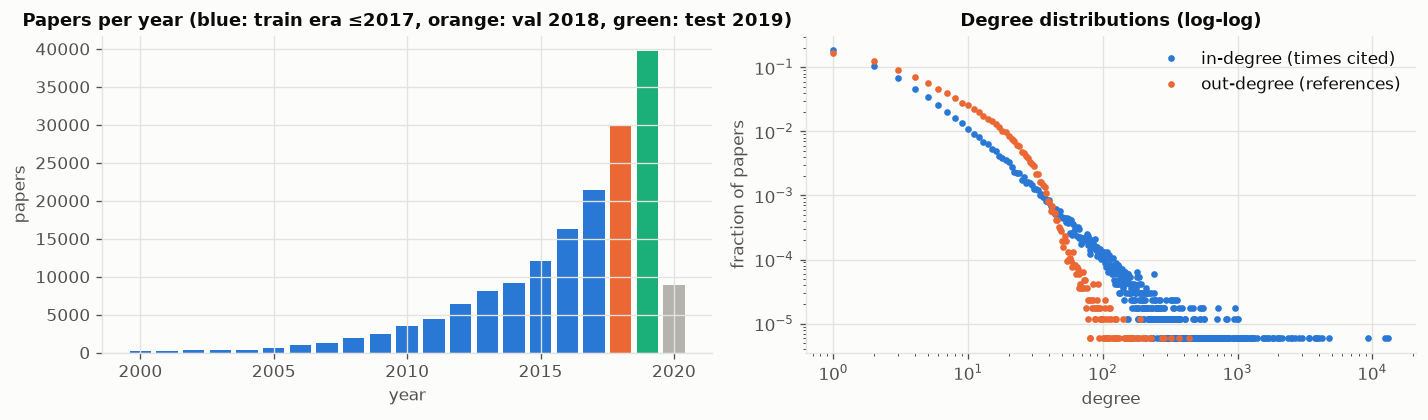

,count,mean,std,min,50%,90%,99%,max,share with 0
in-degree,169343.0,6.89,67.60,0.0,1.0,12.0,87.0,13155.0,0.37
out-degree,169343.0,6.89,8.88,0.0,4.0,18.0,37.0,436.0,0.10


In [4]:
years, counts = np.unique(d.year, return_counts=True)
in_deg, out_deg = np.bincount(dst, minlength=d.num_nodes), np.bincount(src, minlength=d.num_nodes)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sel = years >= 2000
col = ["#2a78d6" if y <= 2017 else "#eb6834" if y == 2018 else "#1baf7a" if y == 2019 else "#b5b3ad" for y in years[sel]]
axes[0].bar(years[sel], counts[sel], color=col, width=0.8)
axes[0].set_title("Papers per year (blue: train era ≤2017, orange: val 2018, green: test 2019)")
axes[0].set_xlabel("year"); axes[0].set_ylabel("papers")
for deg, name in ((in_deg, "in-degree (times cited)"), (out_deg, "out-degree (references)")):
    v, c = np.unique(deg[deg > 0], return_counts=True)
    axes[1].loglog(v, c / d.num_nodes, marker="o", markersize=3, linewidth=0, label=name)
axes[1].set_title("Degree distributions (log-log)"); axes[1].set_xlabel("degree"); axes[1].set_ylabel("fraction of papers")
axes[1].legend()
fig.tight_layout(); display(fig); plt.close(fig)

deg = pd.DataFrame({"in-degree": pd.Series(in_deg).describe(percentiles=[.5, .9, .99]),
                    "out-degree": pd.Series(out_deg).describe(percentiles=[.5, .9, .99])}).T
deg["share with 0"] = [(in_deg == 0).mean(), (out_deg == 0).mean()]
display(deg.round(2))

**What the data tells us.** The corpus grows quickly (2019 alone has ~40k papers, more than all papers before 2014), and citations are extremely skewed: the median paper is cited once, 37% are never cited inside the dataset, while a handful of papers are cited thousands of times. This skew is exactly why a popularity baseline is non-trivial and why popularity bias must be measured (Section 7).

## 3. Task formulation and time-aware split

There are no real users in `ogbn-arxiv`, so — as specified in our proposal — **a paper's reference list stands in for a researcher's reading history**:

* A **query** is a paper *P* with at least `min_refs = 5` *eligible* references. A reference is eligible if it is an in-dataset paper published **strictly before** *P* (year(ref) < year(P)).
* *P*'s eligible references are randomly split (fixed seed) into a revealed **history** set (50%) and a hidden **target** set (50%).
* The model receives *P*'s title/abstract and the history, and must rank **all candidates** — every paper with year < year(*P*), excluding *P* itself and the history — so that the targets come first.

**Time-aware split (matches OGB's official split).** Training queries are papers from ≤ 2017, validation queries are from 2018 and test queries are from 2019. Validation and test are capped at 5,000 randomly chosen queries each for speed (the code supports the full sets with one flag). The split is built once, saved to disk, and every model uses the same file.

**Why references with the same year are excluded.** Candidates must be older than the query, otherwise a model could recommend papers that did not exist yet. A same-year target could therefore never be ranked, so only strictly older references count as history/targets (this removes ~13% of references).

In [5]:
split = load_or_build_split(d, cfg)
R_elig = eligible_references(d)
rows = []
for name in ("train", "val", "test"):
    qs = split[name]
    nh, nt = np.diff(qs.hist_ptr), np.diff(qs.tgt_ptr)
    rows.append({"Split": name, "Query years": f"{qs.year.min()}-{qs.year.max()}", "Queries": len(qs),
                 "Mean history size": nh.mean(), "Mean targets": nt.mean(), "Total targets": int(nt.sum()),
                 "Mean candidates": np.mean([(d.year < y).sum() for y in np.unique(qs.year, return_counts=False)])})
split_table = pd.DataFrame(rows).set_index("Split")
display(split_table.round(1))
n_elig = np.diff(R_elig.indptr)
print(f"Eligible references: {R_elig.nnz:,} of {d.edge_index.shape[1]:,} citations ({R_elig.nnz / d.edge_index.shape[1]:.1%})")
print(f"Queries available before the 5,000 cap: val={(d.year == 2018)[n_elig >= 5].sum() if False else int(((d.year == 2018) & (n_elig >= 5)).sum()):,}, "
      f"test={int(((d.year == 2019) & (n_elig >= 5)).sum()):,}")

2026-11-02 15:27:59 | INFO | src.data | Loaded split split_minrefs5_hist0.5_seed0_val5000_test5000.npz


,Query years,Queries,Mean history size,Mean targets,Total targets,Mean candidates
Split,,,,,,
train,2001-2017,21640,4.7,4.8,104742,16722.4
val,2018-2018,5000,6.3,6.4,31880,90941.0
test,2019-2019,5000,7.1,7.2,35885,120740.0


Eligible references: 1,016,324 of 1,166,243 citations (87.1%)
Queries available before the 5,000 cap: val=15,072, test=25,296


### 3.1 Leakage control

Two graphs are built from the directed citations, and **every graph statistic used by any model comes from one of them**:

| Graph | Edges kept | Used for |
|---|---|---|
| **Training graph** | citations made by papers from ≤ 2017 | training node2vec and the GNN; validation-time statistics |
| **Evaluation graph (test)** | citations made by papers published **before 2019**, minus *all* outgoing citations of every validation and test query paper | test-time statistics (popularity counts, co-citation, PageRank, node2vec refit, GNN neighbourhoods) |

For validation the evaluation graph is identical to the training graph. For test it additionally contains the citations of non-query 2018 papers — information that was genuinely available before 2019. Without it, 2018 papers (25% of the test targets) would be isolated nodes. Because every outgoing edge of every evaluation query is removed, **no hidden target edge can ever be seen**, and every edge's citing paper is older than the queries evaluated on that graph. These properties are asserted below by the same functions used in the project's unit tests (`tests/test_leakage.py`).

In [6]:
from tests.test_leakage import check_split_integrity, check_graph_leak_free

train_graph = build_train_graph(d, split)
graphs = {"train": train_graph, "val": build_eval_graph(d, split, "val"), "test": build_eval_graph(d, split, "test")}
check_split_integrity(d, split, cfg["split"])                        # history/targets disjoint, all older than P, etc.
check_graph_leak_free(d, split, graphs["train"], ["val", "test"])    # no query out-edges, no target edges, time-valid
check_graph_leak_free(d, split, graphs["val"], ["val"])
check_graph_leak_free(d, split, graphs["test"], ["test"])

display(pd.DataFrame({
    "Edges": {k: f"{g.num_edges:,}" for k, g in graphs.items()},
    "Share of all citations": {k: f"{g.num_edges / d.edge_index.shape[1]:.1%}" for k, g in graphs.items()},
    "Latest citing year": {k: int(d.year[g.edge_index[0]].max()) for k, g in graphs.items()},
}))
tgt_years = pd.Series(d.year[split.test.tgt_idx]).value_counts(normalize=True).sort_index()
print("All leakage assertions passed.")
print(f"Share of test targets published in 2018: {tgt_years.get(2018, 0):.1%}")

,Edges,Share of all citations,Latest citing year
train,"378,578",32.5%,2017
val,"378,578",32.5%,2017
test,"554,591",47.6%,2018


All leakage assertions passed.
Share of test targets published in 2018: 25.2%


In [7]:
# Sanity check: what would happen if popularity were computed with *future* citations (leaky)?
from src.evaluate import Evaluator
ev = Evaluator(d.year, (10, 20, 50), device="cpu")
qs_demo = split.test.subset(np.arange(1000))
pop_ok = torch.tensor(np.log1p(graphs["test"].in_degree), dtype=torch.float32)
pop_leak = torch.tensor(np.log1p(np.bincount(dst, minlength=d.num_nodes)), dtype=torch.float32)
rows = {}
for name, p in (("time-valid popularity (used)", pop_ok), ("LEAKY popularity, all citations (NOT used)", pop_leak)):
    rows[name] = ev.evaluate(lambda r: p.expand(len(r), -1), qs_demo)["metrics"]
display(pd.DataFrame(rows).T[["recall@20", "ndcg@20", "mrr"]].round(4))

,recall@20,ndcg@20,mrr
time-valid popularity (used),0.0823,0.0823,0.1972
"LEAKY popularity, all citations (NOT used)",0.0909,0.0890,0.2107


Using future citations would inflate even the simplest model (here by ~8% NDCG@20 on 1,000 test queries). Every result in this report uses only the time-valid graphs.

## 4. Methodology

All models implement one interface — `fit(train_graph, features, split)` learns anything trainable from the training graph only, `prepare(eval_graph)` loads time-valid statistics for the split being evaluated, and `score(queries)` returns a score for every node. Masking of ineligible candidates is done by the shared evaluator (Section 5), never by the models.

### 4.1 Popularity baseline (non-personalised)
Score(*c*) = log(1 + number of times *c* is cited in the time-valid evaluation graph). Every query gets the same ranking.

### 4.2 Content-based recommendation
Each paper is represented from its title + abstract by four alternatives:

| Representation | Details |
|---|---|
| TF-IDF | scikit-learn, English stop words, sublinear tf, terms in ≥ 2 and ≤ 50% of documents (65,641 terms) |
| BM25 | Okapi BM25 (k₁ = 1.5, b = 0.75), implemented as a sparse matrix product and unit-tested to match `rank_bm25` exactly |
| OGB features | the provided 128-d averaged skip-gram vectors (raw, and mean-centred) |
| MiniLM | `sentence-transformers/all-MiniLM-L6-v2` sentence embeddings (384-d, cached to disk) |

A query can be represented in three ways, all reported: **(i) own** — *P*'s own text; **(ii) history** — the mean of the history papers' vectors; **(iii) combo** — α·own + (1 − α)·history (both L2-normalised, equivalent to a weighted sum of cosine similarities; BM25 mixes max-normalised score vectors). α is tuned on validation.

> **Implementation note (scope decision).** The proposal planned SPECTER2 (`allenai/specter2_base`) embeddings. Encoding 169k abstracts with SPECTER2 took > 4 hours on our hardware (Apple M4, no CUDA), so we froze the scope and used MiniLM for every text-dependent model, including the GNN. SPECTER2 support is implemented and resumable (see README).

### 4.3 Graph-based recommendation
All graph statistics come from the time-valid evaluation graph. With *A* the directed adjacency (A[i, j] = 1 if *i* cites *j*) and *h* the history indicator vector:

* **Co-citation:** score(*c*) = Σ_{x ∈ H} #papers citing both *x* and *c* = (h Aᵀ A)[c].
* **Bibliographic coupling:** score(*c*) = Σ_{x ∈ H} #references shared by *x* and *c* = (h A Aᵀ)[c]. We also report the sum of both.
* **Personalized PageRank (PPR):** random walk with restart probability α to the history set, walking along citations in both directions, 20 power iterations, batched as sparse-dense products. α ∈ {0.1, 0.25, 0.5} tuned on validation (chosen: α = 0.25).
* **node2vec:** 128-d embeddings (walk length 20, context 10, p = q = 1) trained on the observed graph of each evaluation split; a query is the mean of its history embeddings. Trained with 3 seeds.

Integer co-citation/coupling counts are tie-broken by popularity; nodes that a graph method cannot reach are back-filled with popularity *below* all reached nodes.

### 4.4 Graph Neural Network (inductive directional GraphSAGE)
**Node features:** MiniLM text embeddings. **Graph:** the directed citation graph; each layer has *separate* weights for "papers I cite" (references) and "papers that cite me" (citers), so edge direction is preserved:

h⁰ᵥ = W_in xᵥ (+ a learnable ID embedding for papers seen in training),
hˡᵥ = hˡ⁻¹ᵥ + GELU(LayerNorm(W_self hˡ⁻¹ᵥ + W_ref · mean_{u ∈ refs(v)} hˡ⁻¹ᵤ + W_cit · mean_{u ∈ citers(v)} hˡ⁻¹ᵤ)),
zᵥ = normalise(W_out hᴸᵥ), with L = 2 layers and 256 hidden units.

**Cold-start queries.** A test paper has no edges. Its embedding is computed *inductively* by treating it as a temporary node whose only neighbours are its history papers (as references) and which has no citers: g⁰ = W_in x_P, gˡ = gˡ⁻¹ + GELU(LayerNorm(W_self gˡ⁻¹ + W_ref · mean_{h ∈ H} hˡ⁻¹ₕ)), q = normalise(W_out gᴸ). A unit test verifies that this equals the item embedding of a paper that cites exactly its history. Target edges are never used. The final score is ⟨q, z_c⟩ + λ·cos(x_P, x_c) with a learnable λ (a text "skip" term).

**Training (mimics evaluation exactly).** Each epoch, 50% of training-era papers become *pseudo-queries*: **all** their outgoing edges are removed from the message-passing graph, and their references are split 50/50 into history and targets. The model is trained with mini-batch neighbour sampling (PyG `NeighborLoader`, fan-out [10, 5]) and a sampled-softmax loss of each (query, target) pair against 512 shared random time-valid negatives (temperature 0.1). BPR and BCE losses and text-similar *hard negatives* are implemented as options; Section 7.4 compares them. Adam (lr 10⁻³), early stopping on validation NDCG@20 (patience 3), 3 seeds.

### 4.5 Hybrid score fusion
For each query, each component's scores are normalised over the time-eligible candidates and combined linearly:

S(P, c) = w_text · norm(S_text(P, c)) + w_graph · norm(S_graph(P, c)) + w_pop · norm(S_pop(c)),

with S_text = MiniLM combo similarity, S_graph = PPR and S_pop = popularity. Two normalisations are compared: per-query z-score and **log-rank** (norm = −log rank of *c* in that component's ranking). The weights and normalisation are chosen by grid search on validation NDCG@20 (1,500 validation queries); the test set is used once, with the chosen weights. A second fusion adds the trained GNN as a component (GNN + PPR, and GNN + text + PPR).

In [8]:
# Core of the hybrid model, shown for reference (full code: src/models/gnn.py and src/models/fusion.py)
import inspect
from src.models.gnn import Encoder
from src.models.fusion import ScoreFusion
print(inspect.getsource(Encoder.queries))
print(inspect.getsource(ScoreFusion.score_batch))

    def queries(self, x_q, hist_hs: list[torch.Tensor], seg: torch.Tensor):
        B = x_q.shape[0]
        g = self.inp(x_q)
        for l, layer in enumerate(self.layers):
            agg = scatter(hist_hs[l], seg, 0, dim_size=B, reduce="mean")
            g = layer.combine(g, agg, None)
        return self.project(g)

    def score_batch(self, qs, rows):
        out = None
        for key, w in self.params["weights"].items():
            if w == 0:
                continue
            s = w * self._normalised(key, qs, rows)
            out = s if out is None else out + s
        return out



## 5. Evaluation methodology

**Candidate set.** For query *P*: all papers with year < year(*P*), minus *P* and its history (≈ 101k candidates for 2018 queries and ≈ 120k for 2019 queries). **Relevance:** the hidden targets (binary). **Full ranking:** every model scores every candidate — no sampled negatives — and the exact rank of every target is computed. Score ties are broken by a fixed seeded random order shared by all models. Scoring runs in batches of 256 queries; no N×N matrix is ever built.

**Metrics** (averaged over queries; K ∈ {10, 20, 50}):

* **Recall@K** = (number of targets in the top K) / (number of targets).
* **NDCG@K** = Σ_{targets ranked ≤ K} 1/log₂(rank + 1), divided by the best achievable value for that query (all targets at the top). It rewards placing relevant papers near the top. **NDCG@20 is our primary metric** and the model-selection criterion.
* **MRR** = 1 / (rank of the first target in the full ranking).

**Model selection.** Every hyper-parameter (α for query mixing, PPR restart, fusion weights/normalisation, GNN epoch) is chosen on the 2018 validation queries. The 2019 test queries are evaluated once per configuration. Trained models (node2vec, GNN) are reported as mean ± std over 3 seeds.

The metric code is verified against hand-computed examples (`tests/test_metrics.py`); one of them is reproduced here:

In [9]:
from src.data import QuerySet
toy_years = np.array([2000, 2000, 2001, 2001, 2002, 2003])
toy = QuerySet.from_lists([5], [2003], [np.array([0])], [np.array([2, 4])])   # paper 5, history {0}, targets {2, 4}
toy_scores = np.array([[9.0, 1.0, 5.0, 7.0, 3.0, 100.0]], dtype=np.float32)
out = Evaluator(toy_years, ks=(1, 2, 3)).evaluate(toy_scores, toy, return_per_query=True)
print("Eligible candidates: 1,2,3,4 (history 0 and the query itself are excluded)")
print("Ranking: 3 (7.0) > 2 (5.0) > 4 (3.0) > 1 (1.0)  -> target ranks", out["target_ranks"][0].tolist())
display(pd.Series(out["metrics"]).round(4).to_frame("value").T)
print("Hand-computed: Recall@2 = 1/2, MRR = 1/2, NDCG@3 = (1/log2(3) + 1/log2(4)) / (1 + 1/log2(3)) =",
      round((1 / np.log2(3) + 1 / np.log2(4)) / (1 + 1 / np.log2(3)), 4))

Eligible candidates: 1,2,3,4 (history 0 and the query itself are excluded)
Ranking: 3 (7.0) > 2 (5.0) > 4 (3.0) > 1 (1.0)  -> target ranks [2.0, 3.0]


,recall@1,ndcg@1,recall@2,ndcg@2,recall@3,ndcg@3,mrr
value,0.0,0.0,0.5,0.3869,1.0,0.6934,0.5


Hand-computed: Recall@2 = 1/2, MRR = 1/2, NDCG@3 = (1/log2(3) + 1/log2(4)) / (1 + 1/log2(3)) = 0.6934


## 6. Results

The table reports **test-set** (2019 queries) results for every model and query representation. Bold marks the best value per column; trained models show mean ± std over 3 seeds. The chosen validation-tuned hyper-parameters are given in brackets.

In [10]:
from scripts.make_tables import collect
NAMES = {"popularity": "Popularity", "tfidf": "TF-IDF", "bm25": "BM25", "ogb_features": "OGB features (raw)",
         "ogb_centered": "OGB features (centred)", "minilm": "MiniLM embeddings", "cocitation": "Co-citation / coupling",
         "ppr": "Personalized PageRank", "node2vec": "node2vec", "gnn": "GNN (GraphSAGE, MiniLM features)",
         "fusion": "Fusion: MiniLM + PPR (+ popularity)", "fusion_gnn": "Fusion: GNN + PPR (+ MiniLM)"}
METRICS = ["recall@10", "recall@20", "recall@50", "ndcg@10", "ndcg@20", "ndcg@50", "mrr"]
test_df = collect(ROOT / "results" / "runs", "test")

def fmt_table(df):
    out = df.copy()
    out["Model"] = out["model"].map(NAMES).fillna(out["model"])
    out["Variant"] = out["variant"] + out["chosen"].map(lambda c: f" [{c}]" if c else "")
    for mtr in METRICS:
        out[mtr] = [f"{v:.4f}" + (f" ± {s:.4f}" if n > 1 else "") for v, s, n in zip(df[mtr], df[mtr + "_std"], df["seeds"])]
    return out.set_index(["family", "Model", "Variant"])[METRICS]

def bold_max(col, raw):
    best = raw.max()
    return ["font-weight:700" if abs(v - best) < 1e-12 else "" for v in raw]

styled = fmt_table(test_df).style
for mtr in METRICS:
    styled = styled.apply(lambda c, mtr=mtr: bold_max(c, test_df[mtr].values), subset=[mtr])
display(styled)

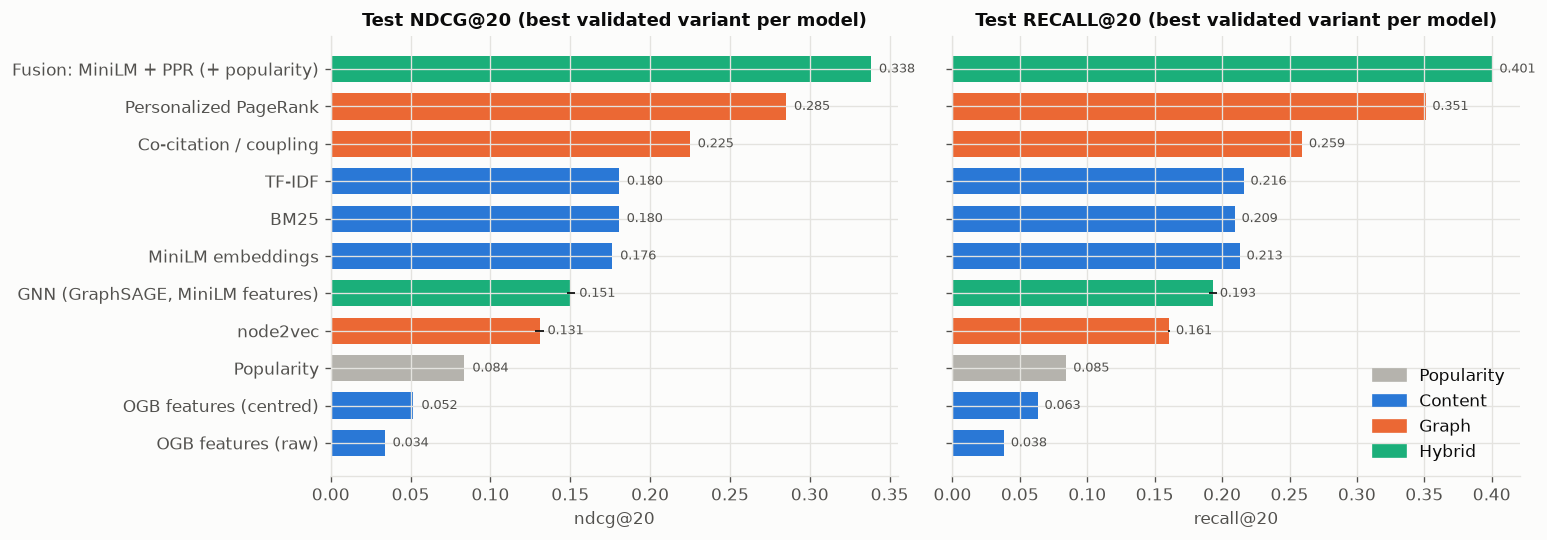

In [11]:
# Best variant per model (chosen on validation NDCG@20), test NDCG@20 and Recall@20
val_df = collect(ROOT / "results" / "runs", "val")
best_rows = []
for model, g in test_df.groupby("model"):
    vg = val_df[val_df.model == model]
    v = vg.loc[vg["ndcg@20"].idxmax(), "variant"]
    best_rows.append(g[g.variant == v].iloc[0])
best = pd.DataFrame(best_rows).sort_values("ndcg@20")
fam_color = {"Popularity": "#b5b3ad", "Content": "#2a78d6", "Graph": "#eb6834", "Hybrid": "#1baf7a"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, mtr in zip(axes, ("ndcg@20", "recall@20")):
    y = np.arange(len(best))
    ax.barh(y, best[mtr], xerr=best[mtr + "_std"], color=[fam_color.get(f, "#888") for f in best.family],
            height=0.7, error_kw={"elinewidth": 1})
    for yi, v in zip(y, best[mtr]):
        ax.text(v + 0.005, yi, f"{v:.3f}", va="center", fontsize=8, color="#52514e")
    ax.set_yticks(y); ax.set_yticklabels([NAMES.get(m, m) for m in best.model])
    ax.set_title(f"Test {mtr.upper()} (best validated variant per model)"); ax.set_xlabel(mtr)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_color.values()]
axes[1].legend(handles, fam_color.keys(), loc="lower right")
fig.tight_layout(); display(fig); plt.close(fig)

### 6.1 Discussion of the main results

1. **Content beats popularity by a wide margin.** The best text models roughly double popularity: TF-IDF combo NDCG@20 = 0.180, BM25 combo = 0.180, MiniLM combo = 0.176 vs. popularity = 0.084. Classical sparse retrieval is as good as the small sentence-embedding model here, because CS abstracts share precise technical vocabulary. The provided OGB features are the exception (NDCG@20 = 0.034 raw, 0.052 mean-centred, both below popularity): averaged skip-gram vectors are highly anisotropic (all vectors point in nearly the same direction), so cosine similarity carries little information.

2. **The citation graph is the strongest single signal.** Co-citation alone reaches NDCG@20 = 0.222 and Personalized PageRank 0.285 (Recall@50 = 0.505) — +62% over the best text model. Papers cited by the same papers as a researcher's history are very likely to be cited by the researcher as well. Bibliographic coupling (shared references) is much weaker (0.074), and node2vec (0.131 ± 0.003) loses to the simple heuristics: averaging a few history embeddings blurs the precise, local co-citation evidence that PPR exploits directly.

3. **Text and graph are complementary: fusion is the best model.** The validation-tuned fusion of MiniLM and PPR reaches NDCG@20 = 0.330 (+16% over PPR), and adding a small popularity term gives the best model overall: NDCG@20 = **0.338**, Recall@20 = 0.401 and MRR = 0.517 (+19% NDCG@20 over PPR, +92% over MiniLM). Normalisation is critical: with z-scores the fused model is *worse* than PPR alone, because PPR's heavy-tailed scores collapse to near-constant z-values; log-rank normalisation makes the components commensurable (Section 7.3).

4. **The GNN learns a real hybrid signal but does not beat PPR on its own.** The inductive GraphSAGE model reaches NDCG@20 = 0.151 ± 0.003 on test — comparable to the text models and better than node2vec, but well below PPR. On validation it is slightly better than MiniLM (0.205 vs. 0.196) but on test it is below it (0.151 vs. 0.176). The breakdowns in Section 7.7 show why: on test the GNN fills 63% of its top-10 lists with 2018 papers (only 25% of targets are from 2018) — papers that never appeared as candidates during training or validation and have essentially no learned ID embedding.

## 7. Ablation study and error analysis

### 7.1 Text-only vs. graph-only vs. hybrid
The most direct test of the research question: the best validated model from each family, evaluated on the same test queries.

In [12]:
def row(key, label, family):
    lbl, var = key.split("/")
    r = json.loads((ROOT / "results" / "runs" / lbl / f"{var}.json").read_text())["test"]
    return {"Family": family, "Model": label, **{k: r[k] for k in ("recall@20", "ndcg@20", "mrr")}}

ablation_rows = [
    row("popularity/default", "Popularity", "None (non-personalised)"),
    row("minilm/combo", "MiniLM (own + history)", "Text only"),
    row("tfidf/combo", "TF-IDF (own + history)", "Text only"),
    row("ppr/default", "Personalized PageRank", "Graph only"),
    row("fusion/text_graph", "MiniLM + PPR", "Text + graph"),
    row("fusion/text_graph_pop", "MiniLM + PPR + popularity", "Text + graph + popularity"),
    row("gnn/default", "GNN (text features + graph)", "Learned hybrid"),
]
for k, lab in (("fusion_gnn/gnn_graph", "GNN + PPR"), ("fusion_gnn/gnn_text_graph", "GNN + MiniLM + PPR")):
    if (ROOT / "results" / "runs" / k.split("/")[0] / f"{k.split('/')[1]}.json").exists():
        ablation_rows.append(row(k, lab, "Learned hybrid + graph"))
abl_df = pd.DataFrame(ablation_rows).set_index(["Family", "Model"])
base = abl_df.loc[("Graph only", "Personalized PageRank"), "ndcg@20"]
abl_df["NDCG@20 vs PPR"] = (abl_df["ndcg@20"] / base - 1).map(lambda x: f"{x:+.1%}")
display(abl_df.round(4))
fg = json.loads((ROOT / "results" / "gnn_dev" / "fusion_gnn_validation.json").read_text())
display(Markdown("**GNN as a fusion component (validation only — test evaluation not run, see README):**"))
display(pd.DataFrame({"GNN + PPR": fg["gnn_graph"]["val"], "GNN + MiniLM + PPR": fg["gnn_text_graph"]["val"],
                      "MiniLM + PPR + popularity (for comparison)": json.loads((ROOT / "results" / "runs" / "fusion" / "text_graph_pop.json").read_text())["val"]}).T[["recall@20", "ndcg@20", "mrr"]].round(4))

recall@20  ndcg@20  \
Family                    Model                                             
None (non-personalised)   Popularity                      0.0846   0.0837   
Text only                 MiniLM (own + history)          0.2131   0.1762   
                          TF-IDF (own + history)          0.2160   0.1804   
Graph only                Personalized PageRank           0.3510   0.2851   
Text + graph              MiniLM + PPR                    0.3946   0.3300   
Text + graph + popularity MiniLM + PPR + popularity       0.4007   0.3383   
Learned hybrid            GNN (text features + graph)     0.1933   0.1506   

                                                          mrr NDCG@20 vs PPR  
Family                    Model                                               
None (non-personalised)   Popularity                   0.1966         -70.6%  
Text only                 MiniLM (own + history)       0.3176         -38.2%  
                          TF-IDF (own + history)       0.3228         -36.7%  
Graph only                Personalized PageRank        0.4307          +0.0%  
Text + graph              MiniLM + PPR                 0.5014         +15.7%  
Text + graph + popularity MiniLM + PPR + popularity    0.5171         +18.7%  
Learned hybrid            GNN (text features + graph)  0.2560         -47.2%

**GNN as a fusion component (validation only — test evaluation not run, see README):**

,recall@20,ndcg@20,mrr
GNN + PPR,0.4545,0.3749,0.5354
GNN + MiniLM + PPR,0.4587,0.3784,0.5396
MiniLM + PPR + popularity (for comparison),0.4576,0.3766,0.5366


### 7.2 How should the query be represented?
For content models we compare using only the query paper's own text, only the mean of its history, or a validation-tuned mix.

In [13]:
qrows = []
for lbl in ("tfidf", "bm25", "ogb_centered", "minilm"):
    for var in ("own", "history", "combo"):
        p = ROOT / "results" / "runs" / lbl / f"{var}.json"
        if p.exists():
            r = json.loads(p.read_text())
            qrows.append({"Model": NAMES[lbl], "Query": var, "alpha": r["runs"][0]["params"].get("alpha") if var == "combo" else "",
                          "NDCG@20": r["test"]["ndcg@20"], "Recall@20": r["test"]["recall@20"], "MRR": r["test"]["mrr"]})
qdf = pd.DataFrame(qrows)
display(qdf.pivot(index="Model", columns="Query", values="NDCG@20")[["own", "history", "combo"]].round(4))

Query,own,history,combo
Model,,,
BM25,0.1529,0.1309,0.1803
MiniLM embeddings,0.1646,0.1302,0.1762
OGB features (centred),0.0388,0.0389,0.0518
TF-IDF,0.1554,0.1294,0.1804


In every content model the query paper's **own text is a better query than its history**, and the **validation-tuned combination is best**: it improves NDCG@20 over own text by +7% to +33% (TF-IDF +16%, BM25 +18%, MiniLM +7%). The chosen weight on the paper's own text is α = 0.5–0.75: the abstract describes the topic precisely, while the history adds the specific context of the researcher's reading.

### 7.3 Fusion weights and normalisation (validation)

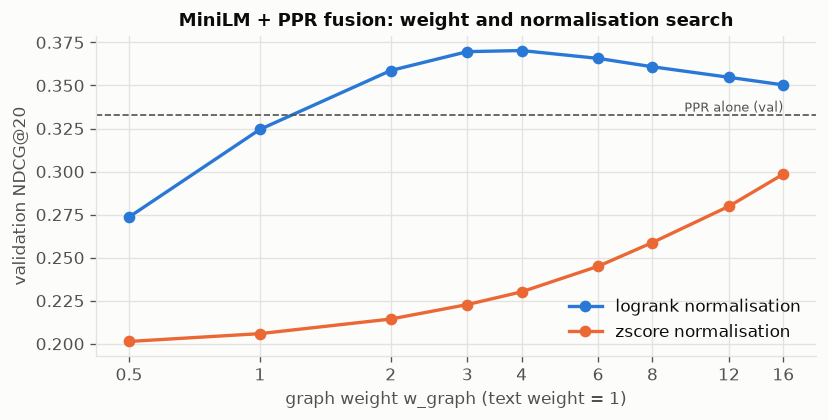

Chosen (text+graph): logrank {'w_pop': 0.0, 'w_graph': 4.0}
Chosen (text+graph+popularity): {'w_graph': 4.0, 'w_pop': 0.25}


In [14]:
fus = json.loads((ROOT / "results" / "runs" / "fusion" / "text_graph.json").read_text())["runs"][0]["tuning"]
tdf = pd.DataFrame([{**t["params"], "ndcg@20": t["ndcg@20"]} for t in fus])
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, (norm, g) in enumerate(tdf.groupby("norm")):
    ax.plot(g["w_graph"], g["ndcg@20"], marker="o", markersize=6, label=f"{norm} normalisation", color=SERIES[i])
ppr_val = json.loads((ROOT / "results" / "runs" / "ppr" / "default.json").read_text())["val"]["ndcg@20"]
ax.axhline(ppr_val, color="#52514e", linestyle="--", linewidth=1)
ax.text(tdf.w_graph.max(), ppr_val, " PPR alone (val)", va="bottom", ha="right", fontsize=8, color="#52514e")
ax.set_xscale("log"); ax.set_xticks(sorted(tdf.w_graph.unique())); ax.set_xticklabels([f"{w:g}" for w in sorted(tdf.w_graph.unique())])
ax.minorticks_off(); ax.set_xlabel("graph weight w_graph (text weight = 1)"); ax.set_ylabel("validation NDCG@20")
ax.set_title("MiniLM + PPR fusion: weight and normalisation search"); ax.legend()
fig.tight_layout(); display(fig); plt.close(fig)
f2 = json.loads((ROOT / "results" / "runs" / "fusion" / "text_graph_pop.json").read_text())["runs"][0]
print("Chosen (text+graph):", json.loads((ROOT / "results" / "runs" / "fusion" / "text_graph.json").read_text())["runs"][0]["params"].get("norm"),
      {k: v for k, v in json.loads((ROOT / "results" / "runs" / "fusion" / "text_graph.json").read_text())["runs"][0]["params"].items() if k.startswith("w_")})
print("Chosen (text+graph+popularity):", {k: v for k, v in f2["params"].items() if k.startswith("w_")})

With z-score normalisation the fused model never reaches PPR alone, regardless of the weight. PPR assigns tiny scores to most of the graph and popularity back-fill values to unreachable papers, so after z-scoring almost every reached paper gets the same value and the PPR ordering is lost. Log-rank normalisation compares the two components on the scale of *positions in their rankings*, which is robust to these heavy tails; the optimum gives the graph a much larger weight than text, i.e. text mostly re-orders and fills in the graph's ranking.

### 7.4 GNN design choices and training curves

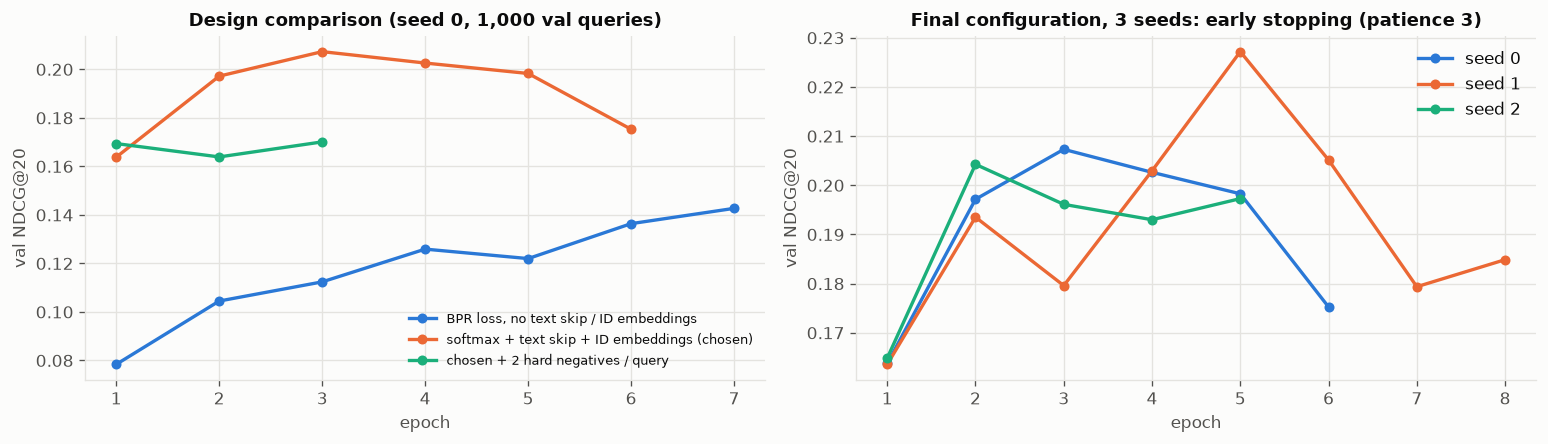

,val NDCG@20,test NDCG@20,test Recall@20,test MRR
seed,,,,
0,0.1993,0.1471,0.1892,0.2518
1,0.2184,0.1516,0.1955,0.2558
2,0.1960,0.1531,0.1953,0.2603


In [15]:
dc = json.loads((ROOT / "results" / "gnn_dev" / "design_comparison.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
labels = {"B_bpr_plain": "BPR loss, no text skip / ID embeddings", "A_softmax_textskip_id": "softmax + text skip + ID embeddings (chosen)",
          "C_A_plus_hard_negatives": "chosen + 2 hard negatives / query"}
for i, (k, v) in enumerate(dc["configs"].items()):
    e = np.arange(1, len(v["val_ndcg20_by_epoch"]) + 1)
    axes[0].plot(e, v["val_ndcg20_by_epoch"], marker="o", markersize=5, label=labels[k], color=SERIES[i])
axes[0].set_title("Design comparison (seed 0, 1,000 val queries)"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("val NDCG@20")
axes[0].legend(fontsize=8)
g = json.loads((ROOT / "results" / "runs" / "gnn" / "default.json").read_text())
for i, run in enumerate(g["runs"]):
    h = run.get("training_history") or []
    if h:
        axes[1].plot([x["epoch"] for x in h], [x["val_ndcg@20"] for x in h], marker="o", markersize=5,
                     label=f"seed {run['seed']}", color=SERIES[i])
axes[1].set_title("Final configuration, 3 seeds: early stopping (patience 3)"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("val NDCG@20")
if any(r.get("training_history") for r in g["runs"]): axes[1].legend()
fig.tight_layout(); display(fig); plt.close(fig)
display(pd.DataFrame([{"seed": r["seed"], "val NDCG@20": r["val"]["ndcg@20"], "test NDCG@20": r["test"]["ndcg@20"],
                       "test Recall@20": r["test"]["recall@20"], "test MRR": r["test"]["mrr"]} for r in g["runs"]]).set_index("seed").round(4))

Three design findings: (i) **BPR against random negatives is too easy** — the training loss falls below 0.03 after two epochs and validation NDCG@20 only creeps up to ≈0.14 after seven epochs; a sampled-softmax (InfoNCE) loss over the same negatives, together with a learnable text-similarity skip term and node ID embeddings, raises it to ≈0.21. (ii) **Hard negatives** (text-similar older papers the query does not cite) did *not* help in our runs; a likely reason is that many of them are relevant papers the author simply did not cite, so treating them as negatives adds label noise. (iii) The model **overfits after 2–5 epochs** (best epochs 3, 5 and 2 for the three seeds; training loss keeps falling while validation NDCG drops), which is why early stopping on validation NDCG@20 matters.

### 7.5 Effect of the time mask
The time mask restricts candidates to papers published before the query. Removing it adds the ~48,600 papers from 2019–2020 as candidates — papers that could never be cited by a 2019 paper's reference list in reality.

In [16]:
tm = json.loads((ROOT / "results" / "ablations" / "time_mask.json").read_text()) if (ROOT / "results" / "ablations" / "time_mask.json").exists() else {}
if tm:
    tdf = pd.DataFrame({k: {"NDCG@20 with mask": v["time_mask_on"]["ndcg@20"], "NDCG@20 without mask": v["time_mask_off"]["ndcg@20"],
                            "Recall@20 with mask": v["time_mask_on"]["recall@20"], "Recall@20 without mask": v["time_mask_off"]["recall@20"]}
                        for k, v in tm.items()}).T
    tdf["NDCG@20 change"] = (tdf["NDCG@20 without mask"] / tdf["NDCG@20 with mask"] - 1).map(lambda x: f"{x:+.1%}")
    display(tdf.round(4))
else:
    print("time-mask ablation not run")

,NDCG@20 with mask,NDCG@20 without mask,Recall@20 with mask,Recall@20 without mask,NDCG@20 change
popularity/default,0.0837,0.0837,0.0846,0.0846,+0.0%
minilm/combo,0.1762,0.1267,0.2131,0.1639,-28.1%
ppr/default,0.2851,0.2848,0.3510,0.3506,-0.1%
fusion/text_graph_pop,0.3382,0.3383,0.4006,0.4006,+0.0%
gnn/default,0.1471,0.1423,0.1892,0.1843,-3.3%


### 7.6 Sensitivity to the history fraction and the query threshold (not run)
The experiment code supports re-running every model with 25% / 75% of the references revealed as history and with `min_refs` = 3 / 10 (`python scripts/run_ablations.py --parts histfrac minrefs`). To meet the submission deadline we froze the scope before running these two sensitivity studies; they are listed as remaining work in the repository README and are **not** part of the results reported here.

### 7.7 Who benefits? Breakdowns by query and by target popularity
We break test performance down (i) by the number of eligible references of the query, (ii) by how well-connected the query's history is (mean in-degree of the history papers, quartiles), and (iii) per target, by how often the target is cited in the time-valid graph. Finally we measure the popularity of what each model recommends.

**NDCG@20 by number of eligible references of the query** (bucket sizes: 5-7: 1250, 8-11: 1211, 12-19: 1460, 20+: 1079)

,5-7,8-11,12-19,20+
Popularity,0.0558,0.0754,0.0930,0.1127
MiniLM embeddings,0.1894,0.1841,0.1772,0.1509
Personalized PageRank,0.2689,0.2890,0.2874,0.2962
"GNN (GraphSAGE, MiniLM features)",0.1764,0.1632,0.1364,0.1095
Fusion: MiniLM + PPR,0.3054,0.3300,0.3421,0.3419
Fusion: MiniLM + PPR + popularity,0.3115,0.3377,0.3510,0.3525


**NDCG@20 by history connectivity** (quartiles of mean in-degree of the history papers; boundaries 23.9, 100.8, 447.7)

,Q1,Q2,Q3,Q4
Popularity,0.0210,0.0681,0.1111,0.1346
MiniLM embeddings,0.2469,0.1753,0.1398,0.1429
Personalized PageRank,0.3195,0.2728,0.2701,0.2779
"GNN (GraphSAGE, MiniLM features)",0.2470,0.1450,0.1010,0.0953
Fusion: MiniLM + PPR,0.3694,0.3268,0.3072,0.3165
Fusion: MiniLM + PPR + popularity,0.3735,0.3357,0.3173,0.3265


**Share of targets ranked in the top 20, by how often the target is cited** (number of targets: 0: 2,819, 1-4: 5,967, 5-19: 8,069, 20-99: 8,785, 100+: 10,245)

,0,1-4,5-19,20-99,100+
Popularity,0.0000,0.0000,0.0000,0.0000,0.3050
MiniLM embeddings,0.2927,0.2780,0.2408,0.1666,0.0721
Personalized PageRank,0.1518,0.1904,0.2117,0.2920,0.5727
"GNN (GraphSAGE, MiniLM features)",0.3104,0.2051,0.1798,0.1445,0.0783
Fusion: MiniLM + PPR,0.2015,0.2656,0.2947,0.3662,0.5295
Fusion: MiniLM + PPR + popularity,0.1770,0.2420,0.2772,0.3636,0.5857


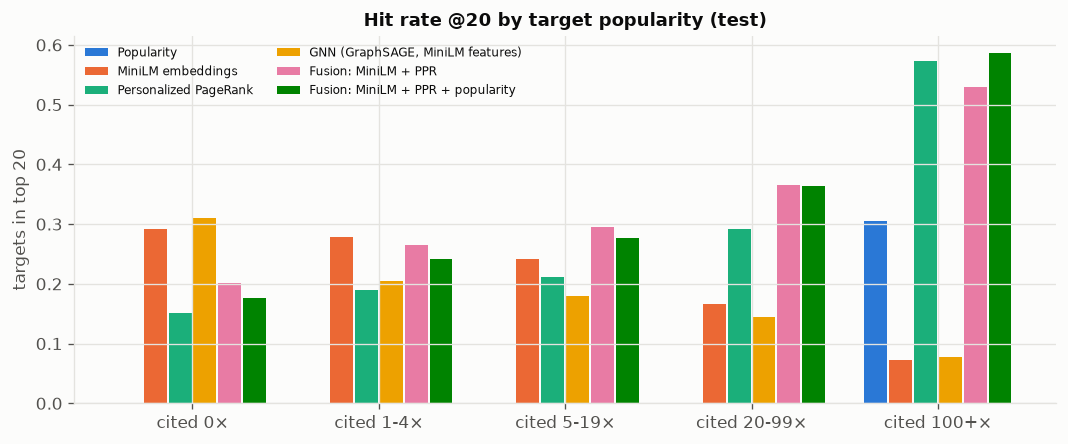

**Popularity of recommendations** — for reference, the true targets have a mean popularity percentile of 0.88 and 41.3% of them are in the top-1% most cited papers.

,Mean popularity percentile of top-10,Share of top-10 in top-1% most cited,Unique papers in all top-10 lists,Median times cited (top-10)
Popularity,1.000,1.000,17.0,2172.0
MiniLM embeddings,0.650,0.061,22002.0,2.0
Personalized PageRank,0.867,0.544,15174.0,72.0
"GNN (GraphSAGE, MiniLM features)",0.477,0.060,20117.0,0.0
Fusion: MiniLM + PPR,0.844,0.442,16626.0,25.0
Fusion: MiniLM + PPR + popularity,0.882,0.537,14889.0,60.0


**Share of top-10 recommendations published in 2018** (the year just before the test queries; 25.2% of the true targets are from 2018)

,share of top-10 from 2018
Popularity,0.000
MiniLM embeddings,0.448
Personalized PageRank,0.192
"GNN (GraphSAGE, MiniLM features)",0.629
Fusion: MiniLM + PPR,0.238
Fusion: MiniLM + PPR + popularity,0.178


In [17]:
bd = json.loads((ROOT / "results" / "ablations" / "breakdowns.json").read_text()) if (ROOT / "results" / "ablations" / "breakdowns.json").exists() else None
if bd:
    LABELS = {"fusion/text_graph": "Fusion: MiniLM + PPR", "fusion/text_graph_pop": "Fusion: MiniLM + PPR + popularity"}
    lab = lambda k: LABELS.get(k, NAMES.get(k.split("/")[0], k))
    def bt(field, metric):
        return pd.DataFrame({lab(k): {b: v[metric] for b, v in r[field].items()} for k, r in bd["models"].items()}).T
    display(Markdown("**NDCG@20 by number of eligible references of the query** (bucket sizes: " +
                     ", ".join(f"{k}: {v}" for k, v in bd["bucket_defs"]["query_refs"].items()) + ")"))
    display(bt("by_query_refs", "ndcg@20").round(4))
    hc = bd["bucket_defs"]["history_connectivity"]
    display(Markdown("**NDCG@20 by history connectivity** (quartiles of mean in-degree of the history papers; boundaries " +
                     ", ".join(f"{x:.1f}" for x in hc["edges_mean_indegree"]) + ")"))
    display(bt("by_history_connectivity", "ndcg@20").round(4))
    tp = bt("by_target_popularity", "hit@20")
    display(Markdown("**Share of targets ranked in the top 20, by how often the target is cited** (number of targets: " +
                     ", ".join(f"{k}: {v:,}" for k, v in bd["bucket_defs"]["target_popularity"].items()) + ")"))
    display(tp.round(4))

    fig, ax = plt.subplots(figsize=(9, 3.8))
    x = np.arange(tp.shape[1]); w = 0.8 / len(tp)
    for i, (name, r) in enumerate(tp.iterrows()):
        ax.bar(x + i * w - 0.4 + w / 2, r.values, width=w * 0.92, label=name, color=SERIES[i % len(SERIES)])
    ax.set_xticks(x); ax.set_xticklabels([f"cited {c}×" for c in tp.columns])
    ax.set_ylabel("targets in top 20"); ax.set_title("Hit rate @20 by target popularity (test)")
    ax.legend(fontsize=7, ncol=2)
    fig.tight_layout(); display(fig); plt.close(fig)

    rp = pd.DataFrame({lab(k): r["recommendation_popularity"] for k, r in bd["models"].items()}).T
    rp.columns = ["Mean popularity percentile of top-10", "Share of top-10 in top-1% most cited", "Unique papers in all top-10 lists", "Median times cited (top-10)"]
    ref = bd["targets_popularity_reference"]
    display(Markdown(f"**Popularity of recommendations** — for reference, the true targets have a mean popularity percentile of "
                     f"{ref['mean_percentile_of_targets']:.2f} and {ref['frac_targets_in_top1pct']:.1%} of them are in the top-1% most cited papers."))
    display(rp.round(3))
    year = d.year
    share = {}
    for k in bd["models"]:
        lbl, var = k.split("/")
        z = np.load(ROOT / "results" / "runs" / lbl / f"{var}_seed0_test_perquery.npz")
        share[lab(k)] = (year[z["topk"]] == 2018).mean()
    tgt = (year[split.test.tgt_idx] == 2018).mean()
    display(Markdown(f"**Share of top-10 recommendations published in 2018** (the year just before the test queries; {tgt:.1%} of the true targets are from 2018)"))
    display(pd.Series(share).to_frame("share of top-10 from 2018").round(3))
else:
    print("breakdowns not run")

**Interpretation.**

* **The targets themselves are popular.** 41% of the hidden targets are among the 1% most-cited papers (mean popularity percentile 0.88), so recommending well-cited papers is partly *correct*, not only bias.
* **Popularity bias differs sharply between signals.** The popularity baseline recommends only 17 distinct papers across all 5,000 queries and can only hit targets cited 100+ times. PPR puts 54% of its top-10 slots on top-1% papers (median 72 citations), MiniLM only 6% (median 2). The MiniLM + PPR fusion is less popularity-biased than PPR (44%, median 25 citations) while being more accurate; adding the popularity component moves it back to PPR's level (54%, median 60) for a small accuracy gain, because many targets really are popular.
* **Text and graph succeed on different targets.** For targets that have never been cited, MiniLM ranks 29% in the top 20 versus 15% for PPR (PPR can still reach uncited papers through *their own* references, because the walk follows citations in both directions). For targets cited 100+ times it is the reverse: PPR 57% vs. MiniLM 7%. The MiniLM + PPR fusion is the best model for every target bucket from 1 to 99 citations (e.g. targets cited 5–19 times: 29% vs. 24% for MiniLM and 21% for PPR) and lies between the two at the extremes (uncited 20%, cited 100+ times 53%). This complementarity is exactly why combining the two signals works.
* **The GNN over-recommends new, uncited papers.** The median citation count of its top-10 recommendations is 0, and 63% of its top-10 slots go to 2018 papers, although only 25% of the targets are from 2018 (MiniLM: 45%, PPR: 19%, fusion: 18%). 2018 papers are never candidates during training or validation; at test time they appear in the graph with essentially no learned ID embedding and an unseen neighbourhood, and the model scores them too highly. This distribution shift explains much of its validation-to-test drop and is the first thing to fix (e.g. ID-embedding dropout during training, or training on a rolling time window).
* **Niche histories are easier.** All personalised models do best when the history consists of rarely-cited papers (lowest connectivity quartile: MiniLM 0.247, PPR 0.319, fusion 0.369) and worse when it consists of heavily-cited papers (top quartile: 0.143, 0.278 and 0.316). The two fusion models are the best models in every quartile. A niche history pins down a specific sub-community, whereas generic "classic" references say little about what else the author needs. Only the popularity baseline improves with connectivity.
* **Longer reference lists.** As the number of references grows, text-only quality falls (MiniLM 0.189 → 0.151) because the targets become more diverse than one abstract can describe, while PPR stays stable or improves (0.269 → 0.296) because a larger history gives it more seeds.
* **Cold start.** Every query is a brand-new paper with no citations (pure query-side cold start), handled through its text and history. On the candidate side, never-cited papers are the hard case for graph methods and text is the main route to them.

## 8. Qualitative examples

Five randomly sampled 2019 test queries (fixed seed), with the recommendations of the best validated hybrid model (MiniLM + PPR + popularity fusion). ✅ marks a hidden target (a paper the query actually cites); "times cited" is computed on the time-valid graph.

In [18]:
q = json.loads((ROOT / "results" / "qualitative.json").read_text()) if (ROOT / "results" / "qualitative.json").exists() else None
if q:
    print("Model:", q["model"])
    for i, ex in enumerate(q["examples"], 1):
        hits = sum(r["hit"] for r in ex["recommendations"])
        display(Markdown(f"#### Example {i}: *{ex['query']['title']}* ({ex['query']['year']})\n"
                         f"**History ({len(ex['history'])} papers):** " + "; ".join(f"{h['title']} ({h['year']})" for h in ex["history"][:6]) +
                         (" …" if len(ex["history"]) > 6 else "") +
                         f"\n\n**Hidden targets:** {ex['num_targets']} · **hits in top 10:** {hits}"))
        recs = pd.DataFrame(ex["recommendations"])[["rank", "hit", "title", "year", "times_cited"]]
        recs["hit"] = recs["hit"].map({True: "✅", False: ""})
        display(recs.set_index("rank"))
else:
    print("qualitative examples not generated")

Model: fusion/text_graph_pop


#### Example 1: *multi task learning for argumentation mining* (2019)
**History (18 papers):** argumentation mining in user generated web discourse (2017); move evaluation in go using deep convolutional neural networks (2014); neural end to end learning for computational argumentation mining (2017); bidirectional lstm crf models for sequence tagging (2015); compositional sequence labeling models for error detection in learner writing (2016); multilingual part of speech tagging with bidirectional long short term memory models and auxiliary loss (2016) …

**Hidden targets:** 17 · **hits in top 10:** 3

,hit,title,year,times_cited
rank,,,,
1,,multi task learning for argumentation mining in low resource settings,2018,2
2,✅,when is multitask learning effective semantic sequence prediction under varying data conditions,2016,13
3,✅,natural language processing almost from scratch,2011,684
4,✅,sequence to sequence learning with neural networks,2014,1606
5,,distributed representations of words and phrases and their compositionality,2013,1910
6,,semi supervised multitask learning for sequence labeling,2017,27
7,,end to end sequence labeling via bi directional lstm cnns crf,2016,96
8,,efficient estimation of word representations in vector space,2013,1415
9,,neural machine translation by jointly learning to align and translate,2014,1901


#### Example 2: *procedural content generation from automatically generating game levels to increasing generality in machine learning* (2019)
**History (8 papers):** cad2rl real single image flight without a single real image (2016); equality of opportunity in supervised learning (2016); procedural content generation via machine learning pcgml (2017); the effectiveness of data augmentation in image classification using deep learning (2017); quantifying generalization in reinforcement learning (2018); autoaugment learning augmentation policies from data (2018) …

**Hidden targets:** 8 · **hits in top 10:** 2

,hit,title,year,times_cited
rank,,,,
1,,the arcade learning environment an evaluation platform for general agents,2013,242
2,,playing atari with deep reinforcement learning,2013,431
3,✅,evolving mario levels in the latent space of a deep convolutional generative adversarial network,2018,5
4,,deep learning for video game playing,2017,5
5,,vizdoom a doom based ai research platform for visual reinforcement learning,2016,37
6,,adam a method for stochastic optimization,2014,5129
7,,batch normalization accelerating deep network training by reducing internal covariate shift,2015,2310
8,,revisiting the arcade learning environment evaluation protocols and open problems for general agents,2017,27
9,✅,a study on overfitting in deep reinforcement learning,2018,4


#### Example 3: *mask scoring r cnn* (2019)
**History (16 papers):** learning to segment object candidates (2015); instance aware semantic segmentation via multi task network cascades (2015); instance sensitive fully convolutional networks (2016); you only look once unified real time object detection (2015); proposal free network for instance level object segmentation (2015); object detection free instance segmentation with labeling transformations (2016) …

**Hidden targets:** 16 · **hits in top 10:** 4

,hit,title,year,times_cited
rank,,,,
1,,mask r cnn,2017,355
2,✅,faster r cnn towards real time object detection with region proposal networks,2015,1611
3,✅,deep residual learning for image recognition,2015,4564
4,✅,masklab instance segmentation by refining object detection with semantic and direction features,2017,7
5,,very deep convolutional networks for large scale image recognition,2014,4748
6,✅,fully convolutional networks for semantic segmentation,2014,1850
7,,fast r cnn,2015,980
8,,semantic image segmentation with deep convolutional nets and fully connected crfs,2014,526
9,,imagenet large scale visual recognition challenge,2014,2195


#### Example 4: *single particle cryo electron microscopy mathematical theory computational challenges and opportunities* (2019)
**History (5 papers):** non unique games over compact groups and orientation estimation in cryo em (2015); apple picker automatic particle picking a low effort cryo em framework (2018); denoising and covariance estimation of single particle cryo em images (2016); estimation in the group action channel (2018); bispectrum inversion with application to multireference alignment (2018)

**Hidden targets:** 5 · **hits in top 10:** 2

,hit,title,year,times_cited
rank,,,,
1,✅,fast steerable principal component analysis,2014,3
2,,the sample complexity of multi reference alignment,2017,4
3,,orthogonal matrix retrieval in cryo electron microscopy,2015,4
4,,covariance estimation using conjugate gradient for 3d classification in cryo em,2015,5
5,,spectral methods from tensor networks,2018,1
6,✅,heterogeneous multireference alignment a single pass approach,2017,2
7,,a representation theory perspective on simultaneous alignment and classification,2016,4
8,,a max cut approach to heterogeneity in cryo electron microscopy,2016,3
9,,continuously heterogeneous hyper objects in cryo em and 3 d movies of many temporal dimensions,2017,3


#### Example 5: *pod positional dependency based word embedding for aspect term extraction* (2019)
**History (8 papers):** dependency recurrent neural language models for sentence completion (2015); recursive neural conditional random fields for aspect based sentiment analysis (2016); improved semantic representations from tree structured long short term memory networks (2015); aspect term extraction with history attention and selective transformation (2018); efficient estimation of word representations in vector space (2013); distributed representations of words and phrases and their compositionality (2013) …

**Hidden targets:** 9 · **hits in top 10:** 1

,hit,title,year,times_cited
rank,,,,
1,✅,unsupervised word and dependency path embeddings for aspect term extraction,2016,8
2,,distributed representations of sentences and documents,2014,485
3,,aspect based sentiment analysis using a two step neural network architecture,2016,1
4,,a unified model for opinion target extraction and target sentiment prediction,2018,0
5,,natural language processing almost from scratch,2011,684
6,,a convolutional neural network for modelling sentences,2014,329
7,,deep residual learning for image recognition,2015,4564
8,,aspect sentiment model for micro reviews,2018,1
9,,convolutional neural networks for sentence classification,2014,397


**Observations.**

* **Two kinds of hits.** Some hits are the *standard references of a sub-field*, which the graph component finds through co-citation: *Faster R-CNN*, *Deep Residual Learning* and *Fully Convolutional Networks* for the instance-segmentation paper (Example 3), or *Natural Language Processing (Almost) from Scratch* and *Sequence to Sequence Learning* for the argumentation-mining paper (Example 1). Others are *topically very close, rarely-cited* papers that the text component finds: *MaskLab* (7 citations, Example 3), *Evolving Mario Levels in the Latent Space of a DCGAN* (5 citations, Example 2), or *Fast Steerable Principal Component Analysis* for the cryo-EM survey (Example 4).
* **The ground truth is incomplete.** Several non-hits are obviously relevant. *Mask R-CNN* is ranked first for *Mask Scoring R-CNN* (a paper that directly extends it), and *Multi-Task Learning for Argumentation Mining in Low-Resource Settings* is ranked first for the multi-task argumentation-mining paper. Neither appears among the query's eligible references in the dataset, so they count as misses, and absolute scores understate how useful the recommendations are.
* **Failure mode: generic popular papers.** When the history contains generic deep-learning papers (Example 2's history mixes game generation with fairness and data augmentation), the graph and popularity components pull in field-wide classics such as *Adam*, *Batch Normalization* and *VGG*. These are cited by many papers but are rarely the specific references a researcher needs. Example 4 (cryo-EM, a niche community) shows the opposite: all ten recommendations are specialised, rarely-cited papers from the right sub-field.

## 9. Limitations and future work

* **Proxy users.** A paper's reference list stands in for a researcher's reading history. Real reading histories are noisier, span several topics and contain papers that are never cited. Our ground truth is also incomplete: a recommended paper that the author did not cite is counted as wrong even when it is relevant.
* **Year-level time stamps.** Publication *year* is the only time information, so same-year references had to be excluded (≈ 11% of citations) and arXiv versions/revisions blur the timeline (1.8% of edges point "into the future").
* **Popularity bias and candidate cold start.** Graph-based models (and therefore the best hybrid) favour already-cited papers and cannot surface brand-new work through the graph. Text is the only route for uncited papers.
* **Text encoder.** For compute reasons we used MiniLM instead of the planned SPECTER2 (a scientific-document encoder trained on citations), which would likely strengthen both the text-only models and the GNN. The GNN was also tuned only lightly (a handful of configurations, 3 seeds).
* **Evaluation subset and variance.** Validation and test use 5,000 randomly sampled queries each (of 15,072 and 25,296 available). The seed-to-seed standard deviation of the trained models is 0.003 NDCG@20 or less, but we did not compute confidence intervals over queries, so very small differences between models should not be over-interpreted.
* **Future work.** SPECTER2 or citation-informed text encoders; learning the fusion weights per query (e.g. a small learning-to-rank model using history connectivity as a feature); diversity/novelty-aware re-ranking to reduce popularity bias; the history-fraction and `min_refs` sensitivity studies; and evaluating on all queries with the `split.max_*_queries=null` option.

## 10. Conclusion

We built a leakage-tested, time-aware benchmark for research-paper recommendation on `ogbn-arxiv` and used it to answer our research question.

* **Content alone helps:** text similarity roughly doubles the popularity baseline (NDCG@20 0.176 vs. 0.084); classical TF-IDF/BM25 are as strong as MiniLM.
* **The citation graph is the strongest single signal:** Personalized PageRank reaches NDCG@20 = 0.285, and simple co-citation beats learned node2vec embeddings.
* **Combining them is best:** validation-tuned fusion of MiniLM and PPR reaches NDCG@20 = 0.330; with a small popularity term it reaches NDCG@20 = 0.338 and Recall@20 = 0.401 — **+19% over the best graph-only model and +92% over the best text-only model**. Text and graph are complementary: the graph finds the established papers of a sub-field, while text finds topically close, rarely-cited papers that the graph ranks low.
* **A more complex model is not automatically better:** our inductive GraphSAGE hybrid (NDCG@20 = 0.151 ± 0.003) learns a useful combined representation but does not beat a well-normalised fusion of two simple, strong components.

**Answer to the research question:** yes — combining semantic and citation-network information gives clearly better recommendations than content-only, graph-only and popularity baselines in a realistic, time-aware evaluation; in our experiments the most effective combination is simple score fusion with rank-based normalisation.

## Appendix A. Hyper-parameters
All values below were chosen on the 2018 validation queries (or fixed a priori); the 2019 test queries were used only for the final evaluation.

In [19]:
import yaml
hp = []
for lbl in ("tfidf", "bm25", "ogb_features", "ogb_centered", "minilm"):
    p = ROOT / "results" / "runs" / lbl / "combo.json"
    if p.exists():
        r = json.loads(p.read_text()); hp.append({"Model": NAMES[lbl], "Chosen on validation": f"alpha = {r['runs'][0]['params']['alpha']}"})
r = json.loads((ROOT / "results" / "runs" / "ppr" / "default.json").read_text())["runs"][0]["params"]
hp.append({"Model": NAMES["ppr"], "Chosen on validation": f"restart alpha = {r['alpha']}, 20 iterations, both directions"})
for v in ("text_graph", "text_graph_pop"):
    p = json.loads((ROOT / "results" / "runs" / "fusion" / f"{v}.json").read_text())["runs"][0]["params"]
    hp.append({"Model": f"Fusion ({v.replace('_', ' + ')})", "Chosen on validation":
               f"norm = {p['norm']}, weights = " + ", ".join(f"{k}={w}" for k, w in p["weights"].items())})
display(pd.DataFrame(hp).set_index("Model"))
print("node2vec:", yaml.safe_load(open(ROOT / "configs" / "baselines.yaml"))["models"][-1]["params"])
print("GNN:", yaml.safe_load(open(ROOT / "configs" / "gnn.yaml"))["gnn"]["params"])

,Chosen on validation
Model,
TF-IDF,alpha = 0.6
BM25,alpha = 0.75
OGB features (raw),alpha = 0.9
OGB features (centred),alpha = 0.5
MiniLM embeddings,alpha = 0.6
Personalized PageRank,"restart alpha = 0.25, 20 iterations, both directions"
Fusion (text + graph),"norm = logrank, weights = text=1.0, graph=4.0, pop=0.0"
Fusion (text + graph + pop),"norm = logrank, weights = text=1.0, graph=4.0, pop=0.25"


node2vec: {'dim': 128, 'walk_length': 20, 'context_size': 10, 'walks_per_node': 5, 'epochs': 2, 'lr': 0.025}
GNN: {'feature': 'minilm', 'hidden': 256, 'out_dim': 256, 'num_layers': 2, 'fanout': [10, 5], 'dropout': 0.1, 'lr': 0.001, 'epochs': 15, 'patience': 3, 'query_frac': 0.5, 'history_frac': 0.5, 'batch_queries': 256, 'num_shared_neg': 512, 'hard_neg_per_query': 0, 'loss': 'softmax', 'tau': 0.1, 'text_skip': True, 'id_emb': True, 'eval_queries': 1000, 'train_device': 'auto'}


## Appendix B. Reproducibility

Environment: Python 3.12, PyTorch 2.5.1, PyTorch Geometric 2.6.1 (exact versions in `requirements.txt`); all seeds are fixed (`configs/default.yaml`). Every expensive artefact (split, embeddings, node2vec, GNN weights) is cached and reused.

```bash
pip install -r requirements.txt                       # + PyG extension wheels, see README
python -m pytest                                      # metric, leakage and model unit tests
python scripts/eda.py                                 # dataset statistics, saves the split
python scripts/embed_text.py --models minilm          # MiniLM embeddings (cached)
python scripts/run_baselines.py                       # all baselines (val tuning -> test)
python scripts/run_baselines.py --config configs/fusion.yaml       # MiniLM + PPR fusion
python scripts/train_gnn.py                           # GNN, 3 seeds
python scripts/run_baselines.py --config configs/fusion_gnn.yaml   # GNN-based fusion
python scripts/run_ablations.py --parts breakdowns timemask qualitative
python scripts/make_tables.py                         # results/tables/main_test.md
python report/build_report.py                         # this report
```

## Appendix C. Validation results

In [20]:
display(fmt_table(val_df))

recall@10  \
family     Model                               Variant                                                                   
Popularity Popularity                          default                                                          0.0820   
Content    BM25                                combo [alpha=0.75]                                               0.1692   
                                               history                                                          0.1309   
                                               own                                                              0.1408   
           MiniLM embeddings                   combo [alpha=0.6]                                                0.1714   
                                               history                                                          0.1326   
                                               own                                                              0.1546   
           OGB features (centred)              combo [alpha=0.5]                                                0.0539   
                                               history                                                          0.0416   
                                               own                                                              0.0372   
           OGB features (raw)                  combo [alpha=0.9]                                                0.0316   
                                               history                                                          0.0229   
                                               own                                                              0.0309   
           TF-IDF                              combo [alpha=0.6]                                                0.1728   
                                               history                                                          0.1314   
                                               own                                                              0.1444   
Graph      Co-citation / coupling              both                                                             0.2289   
                                               cocitation                                                       0.2230   
                                               coupling                                                         0.0910   
           node2vec                            default                                                 0.1313 ± 0.0015   
           Personalized PageRank               default [alpha=0.25]                                             0.3007   
Hybrid     Fusion: MiniLM + PPR (+ popularity) text_graph [norm=logrank, w_pop=0.0, w_graph=4.0]                0.3343   
                                               text_graph_pop [norm=logrank, w_graph=4.0, w_pop=0.25]           0.3372   
           GNN (GraphSAGE, MiniLM features)    default                                                 0.1835 ± 0.0085   

                                                                                                             recall@20  \
family     Model                               Variant                                                                   
Popularity Popularity                          default                                                          0.1076   
Content    BM25                                combo [alpha=0.75]                                               0.2341   
                                               history                                                          0.1909   
                                               own                                                              0.1922   
           MiniLM embeddings                   combo [alpha=0.6]                                                0.2466   
                                               history                            